In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
np.random.seed(42)

n = 1000

x = np.linspace(0, 10, n)
noise = np.random.normal(0, 1.5, n)

y = np.sin(x) + 0.3 * x + noise

data = pd.DataFrame({
    'x': x,
    'y': y
})

print("Кількість записів:", len(data))
data.head()

Кількість записів: 1000


,x,y
0,0.00000,0.745071
1,0.01001,-0.194384
2,0.02002,0.997557
3,0.03003,2.323579
4,0.04004,-0.299189


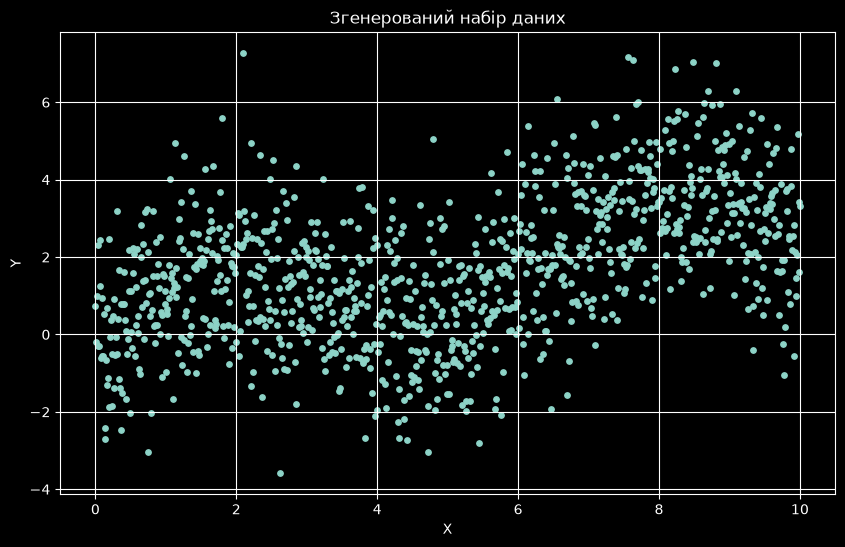

In [3]:
plt.figure(figsize=(10, 6))

plt.scatter(
    data['x'],
    data['y'],
    s=15
)

plt.xlabel('X')
plt.ylabel('Y')
plt.title('Згенерований набір даних')
plt.grid()

plt.show()

In [4]:
scaler = MinMaxScaler()

data['x_normalized'] = scaler.fit_transform(
    data[['x']]
)

print("Мінімальне значення після нормалізації:",
      data['x_normalized'].min())

print("Максимальне значення після нормалізації:",
      data['x_normalized'].max())

data.head()

Мінімальне значення після нормалізації: 0.0
Максимальне значення після нормалізації: 1.0


,x,y,x_normalized
0,0.00000,0.745071,0.000000
1,0.01001,-0.194384,0.001001
2,0.02002,0.997557,0.002002
3,0.03003,2.323579,0.003003
4,0.04004,-0.299189,0.004004


In [6]:
X = data[['x_normalized']]
Y = data['y']
X_train, X_test, y_train, y_test = train_test_split(
    X,
    Y,
    test_size=0.2,
    random_state=42
)

print("Навчальна вибірка:", len(X_train))
print("Тестова вибірка:", len(X_test))

Навчальна вибірка: 800
Тестова вибірка: 200


In [11]:
k_values = [1, 3, 5, 7, 10, 15, 20, 30, 50]
results = []

for k in k_values:
    model = KNeighborsRegressor(n_neighbors=k)

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)

    mse = mean_squared_error(y_test, y_pred)

    rmse = np.sqrt(mse)

    r2 = r2_score(y_test, y_pred)

    results.append({
        'K': k,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R2': r2
    })

results_df = pd.DataFrame(results)

results_df

,K,MAE,MSE,RMSE,R2
0,1,1.731568,4.540331,2.130805,-0.367742
1,3,1.403748,3.020662,1.738005,0.090047
2,5,1.266519,2.505583,1.582903,0.245211
3,7,1.228270,2.377464,1.541903,0.283806
4,10,1.181383,2.263959,1.504646,0.317999
5,15,1.158400,2.155403,1.468129,0.350700
6,20,1.161882,2.169638,1.472969,0.346412
7,30,1.163881,2.145089,1.464612,0.353808
8,50,1.165650,2.162701,1.470612,0.348502


In [13]:
results_df.to_csv(
    'lab02_results.csv',
    index=False
)

In [14]:
best_k = results_df.loc[results_df['RMSE'].idxmin(), 'K']

print("Найкраще значення K:", best_k)

Найкраще значення K: 30


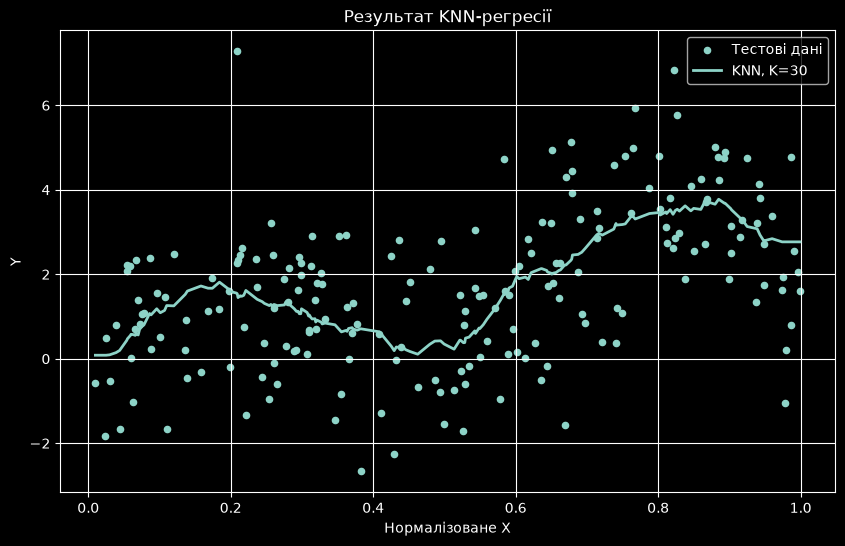

In [15]:
plt.figure(figsize=(10, 6))

plt.scatter(
    X_test['x_normalized'],
    y_test,
    s=20,
    label='Тестові дані'
)

sort_index = np.argsort(X_test['x_normalized'].values)

plt.plot(
    X_test['x_normalized'].values[sort_index],
    y_pred[sort_index],
    linewidth=2,
    label=f'KNN, K={int(best_k)}'
)

plt.xlabel('Нормалізоване X')
plt.ylabel('Y')
plt.title('Результат KNN-регресії')
plt.legend()
plt.grid()
plt.show()